<a href="https://colab.research.google.com/github/TejasDharmale/Neural_computation/blob/main/20261109_SWK_Neural_computation_assignment_2b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: *Neuron models*

In this assignment, we will investigate the Adaptive Exponential (`AdEx`) neuron. The model was presented in the lecture, but as a reminder, it is a 2-dimensional adaptive nonlinear integrate-and-fire model. The sub-threshold dynamics is given by:

$$C_{m} \frac{dV_{m}}{dt} = -G_{\mathrm{L}} (V_{m} - E_{L}) + G_{\mathrm{L}} \Delta_{\mathrm{T}} \mathrm{exp}\left( \frac{(V_{m} - V_{\mathrm{T}})}{\Delta_{\mathrm{T}}} \right) - w + I_{\mathrm{stim}}$$

$$\tau_{w} \frac{dw}{dt} = -w + a (V_{m} - E_{L})$$

Spiking mechanism: when the membrane crosses a hard threshold $V_\text{peak}$ (note that this is not $V_{\mathrm{T}}$), the membrane is reset to $V_{\mathrm{reset}}$ and $w$ is increased by $b$ (which sets the amplitude of spike-triggered adaptation).

For the most readable explanation of this model similar to the above equation see: http://www.scholarpedia.org/article/Adaptive_exponential_integrate-and-fire_model

We will provide an initial set of parameters below.

### General tip:
Throughout be very careful with the units and magnitudes of variables.
We recommend plotting the voltages in mV (so for plotting multiply all voltages by 1e3), and plotting the adaptation currents in pA (so for plotting multiply all w by 1e12). This makes it easier to compare with most literature. You could also simulate your model in mV and pA with appropriate parameter adjustments.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
G_L = 2.*1e-9          # [nS] Leak conductance
tau_m = 20*1e-3 # slightly adjusted from original set to get irregular-like behavior
C_m = G_L*tau_m        # [pF] Membrane capacitance
E_L = -70.*1e-3         # [mV] Resting Membrane Potential
V_reset = -51.*1e-3     # [mV] Reset potential
V_peak = 0.0*1e-3       # [mV] Voltage cutoff (effective threshold)
V_th = -50.*1e-3        # [mV] Threshold
I_e = 65.0*1e-12      # [pA] Input current (constant bias)
tau_w = 100.*1e-3       # [s] adaptation time constant
Delta_T = 2.*1e-3       # [mV] Sharpness of spike initiation
a = 0.5*1e-9             # [nS] sub-threshold adaptation
b = 7.0*1e-12          # [pA] spike-triggered adapation
pars = [C_m, G_L, E_L, V_reset, V_peak, V_th, I_e, tau_w, Delta_T, a, b]

### 1. Model implementation and testing.
**(2 Points total)**

In this exercise, you will implement the AdEx neuron model and run a test simulation driving the neuron with constant current inputs.


#### 1.1. Numerical integration.

Using Euler integration, implement the model and simulate it using the default parameters provided above. This will be similar to the simulations from the first assignment, but require the addition of a voltage reset and adaptation update. It is highly recommended to make a re-usable function here, so you can easily run the model with different parameter sets later.

For this simulation, drive the neuron with a constant input current $I_{e}=500 \mathrm{pA}$ for $200 \mathrm{ms}$ and plot the resulting voltage and adaptation variable. Your solution should be similar to slide 41 from the lecture, although the spiking behavior will be different (note that for plotting purposes I there cut-off all the spikes at -30 mV).  **(1 points)**

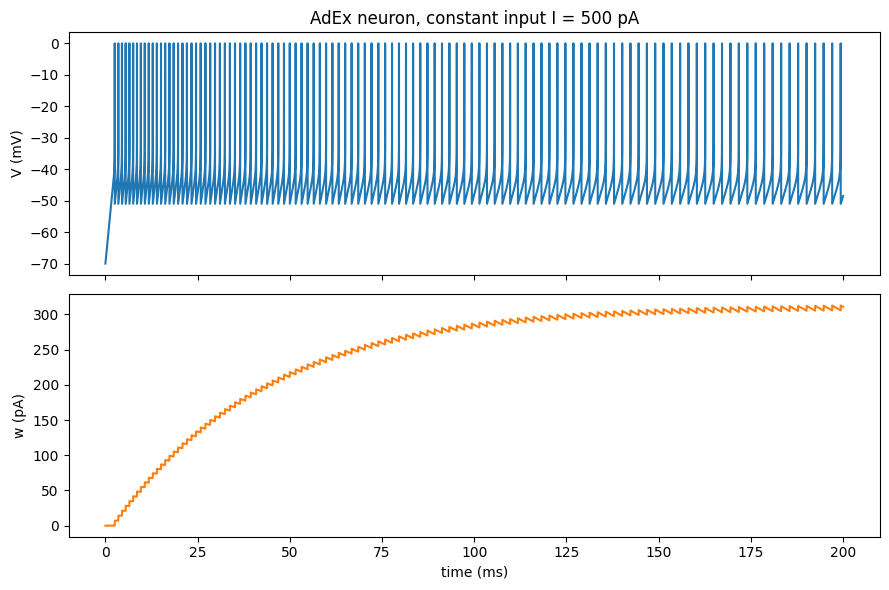

Number of spikes in 200 ms: 111


In [ ]:
def simulate_adex(pars, I_stim, T=0.2, dt=1e-5, V0=None, w0=0.0):
    C_m, G_L, E_L, V_reset, V_peak, V_th, _, tau_w, Delta_T, a, b = pars
    n = int(T/dt)
    t = np.arange(n)*dt
    I = I_stim(t) if callable(I_stim) else np.full(n, I_stim)
    V= np.zeros(n)
    w = np.zeros(n)
    V[0] = E_L if V0 is None else V0
    w[0] = w0
    spikes = []
    for k in range(n-1):
        dV = (-G_L*(V[k]-E_L) + G_L*Delta_T*np.exp((V[k]-V_th)/Delta_T) - w[k] + I[k]) / C_m
        dw = (-w[k] + a*(V[k]-E_L)) / tau_w
        V[k+1] = V[k] + dt*dV
        w[k+1] = w[k] + dt*dw
        if V[k+1] >= V_peak:
            V[k] = V_peak
            V[k+1] = V_reset
            w[k+1] += b
            spikes.append(t[k+1])

    return t, V, w, np.array(spikes)


t, V, w, spikes = simulate_adex(pars, 500e-12, T=0.2)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t*1e3, V*1e3)
ax[0].set_ylabel("V (mV)")
ax[0].set_title("AdEx neuron, constant input I = 500 pA")
ax[1].plot(t*1e3, w*1e12, color="C1")
ax[1].set_ylabel("w (pA)")
ax[1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

print(f"Number of spikes in 200 ms: {len(spikes)}")

In [ ]:
# Implements the AdEx neuron model through forward Euler method integration with a time step size of 0.01 ms.
# At every step, V and w values are updated based on their differential equations, stimulated by the input current I_stim.
# When V value becomes equal to V_peak, a spike is generated, then V value is set to V_reset and w value is incremented by b.
# Here, the neuron is stimulated with a constant input current of 500 pA for 200 ms, where V (mV) and w (pA) values are plotted.

#### 1.2. Firing patterns.

**1.2.1.** Consider the different types of firing patterns described here: Fig. 6.2 at https://neuronaldynamics.epfl.ch/online/Ch6.S1.html. How would you label the firing pattern you observe, and why? Can you explain from the $V$ and $m$ time-courses why the pattern is as it is?  **(0.25 points)**

## Answer to 1.2.1
Label: adapting. The spiking behavior shows adaptation: the neuron spikes very rapidly at the beginning of the stimulation by the 500 pA current injection, with initial interspike intervals of about 1.0 ms; then these intervals increase gradually up to about 2.3 ms at the end and become rhythmic. No initial bursting (no cluster of spikes followed by a pause) and no spike latency exist. The decreasing frequency that finally reaches a steady state is called adaptation.

The rationale behind this type of spiking behavior from the perspective of V and w dynamics. Initially, w = 0, hence the membrane voltage V can only be affected by the leak conductance. Thus, it rapidly increases from V_reset (−51 mV) to V_T; then the exponential term dominates and causes the neuron to fire rapidly. After each spike, w is increased by b = 7 pA, while w decreases between spikes with τ_w = 100 ms, much longer than the interspike interval (about 1 to 2 ms).And since w decays very little during an interspike period and increases in a stepwise fashion, the value of w builds up similarly to a step function. This is so because w enters the voltage equation as −w, and thus the higher the value of w, the lesser the net current (I − w), and thus V will take longer to recover after reset. The subthreshold component a(V − E_L) contributes further to such build up because V is much greater than E_L during repetitive spiking.

Adaptation ends when w is in a steady state of about 310 pA. And since at this point the decay of w over an interspike period equals the value of b added at each spike, then the net driving current (I − w) will be constant, and the interspike period will no longer change.

**1.2.2.** Specify additional parameter sets that correspond to different firing behaviors (consult [this table](https://neuronaldynamics.epfl.ch/online/Ch6.S2.html)). Note that $\tau_m$ is given by $\frac{C_m}{G_L}$. Implement at least two different parameter sets, run the model and plot the states as above. Also note that the irregular pattern can be hard to reproduce, as the model operates in a chaotic regime and relies on very specific simulation settings (integration method and timestep).  **(0.75 points)**

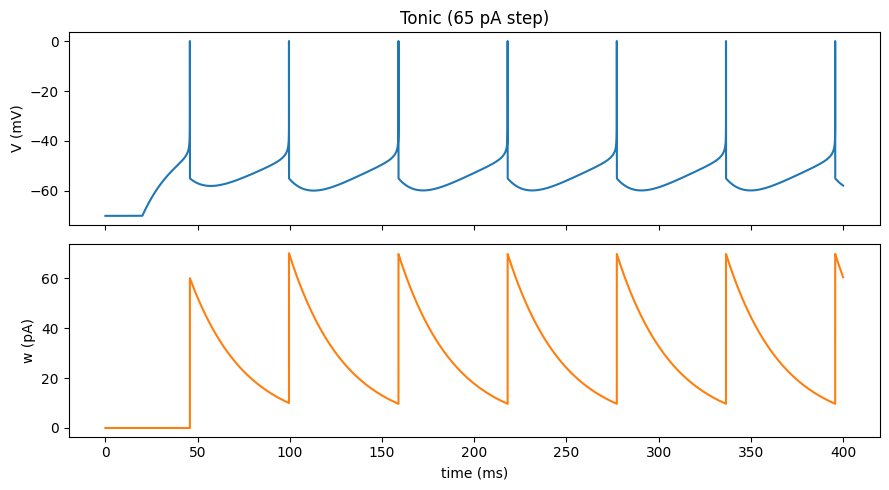

Tonic (65 pA step): 7 spikes, ISIs (ms): [53.7 59.4 59.2 59.2 59.2 59.2]


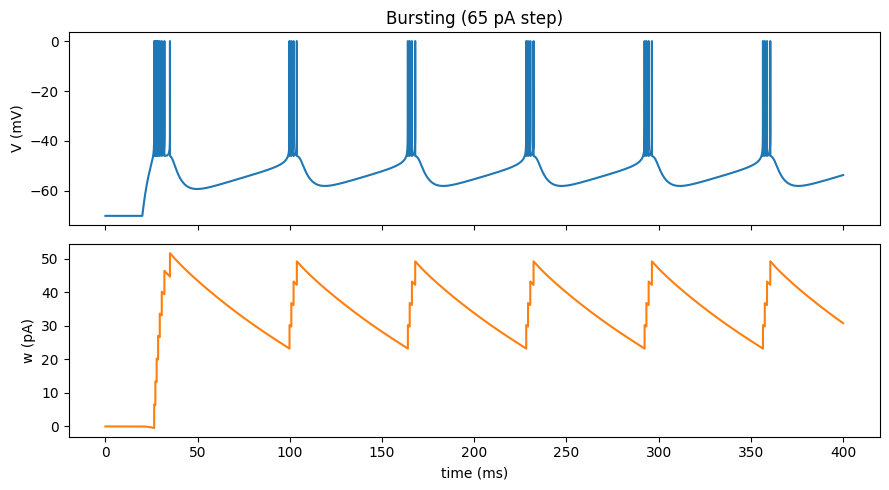

Bursting (65 pA step): 28 spikes, ISIs (ms): [ 0.6  0.7  0.8  0.9  1.1  1.4  3.  64.8  1.   1.2  1.8 60.2  1.   1.2
  1.8 60.2  1.   1.2  1.8 60.2  1.   1.2  1.8 60.2  1.   1.2  1.8]


In [ ]:
def make_pars(tau_m, a, tau_w, b, V_reset, I_e=65e-12, G_L=2e-9):
    return [G_L*tau_m, G_L, -70e-3, V_reset, 0.0, -50e-3, I_e, tau_w, 2e-3, a, b]
pars_tonic    = make_pars(tau_m=20e-3, a=0.0,     tau_w=30e-3,  b=60e-12, V_reset=-55e-3)
pars_bursting = make_pars(tau_m=5e-3,  a=-0.5e-9, tau_w=100e-3, b=7e-12,  V_reset=-46e-3)
def plot_states(pars, title, T=0.4, t_on=0.02):
    step = lambda t: np.where(t >= t_on, pars[6], 0.0)
    t, V, w, spikes = simulate_adex(pars, step, T=T)
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(t*1e3, V*1e3); ax[0].set_ylabel("V (mV)"); ax[0].set_title(title)
    ax[1].plot(t*1e3, w*1e12, color="C1"); ax[1].set_ylabel("w (pA)"); ax[1].set_xlabel("time (ms)")
    plt.tight_layout(); plt.show()
    print(f"{title}: {len(spikes)} spikes, ISIs (ms): {np.round(np.diff(spikes)*1e3, 1)}")

plot_states(pars_tonic, "Tonic (65 pA step)")
plot_states(pars_bursting, "Bursting (65 pA step)")

In [ ]:
# Implements two additional firing regimes by specifying parameter values from Table 6.1 (Neuronal Dynamics): Tonic and Bursting.
# Only tau_m, a, tau_w, b, and V_reset differ between two groups, while C_m can be calculated as tau_m = C_m/G_L.
# The neurons receive 65 pA step current starting at 20 ms in a 400 ms run.
# Time dependence of V (mV) and w (pA) is shown and number of spikes and ISI are displayed.


Two parameter sets from Table 6.1 (Neuronal Dynamics) have been simulated using a 65 pA step current lasting 400 ms.

**Tonic** (τ_m = 20 ms, a = 0, τ_w = 30 ms, b = 60 pA, V_reset = -55 mV): tonic spiking, which consists of regular intervals of firing with a constant ISI of approximately 59 ms. τ_w is quite short relative to the ISI, meaning that w decreases back to nearly zero after every spike. Hence, there is nothing built up and all intervals are identical.

 **Bursting** (τ_m = 5 ms, a = -0.5 nS, τ_w = 100 ms, b = 7 pA, V_reset = -46 mV): bursting into 4 fast spikes at intervals of 60 ms. Due to the high reset value (greater than V_T), these spikes occur in quick succession, until the buildup of w causes the end of the burst. In the meantime, w decreases slowly and when it reaches a sufficiently low value a new burst occurs.

## 2. Input-output functions
**(1.5 Points total)**


The frequency-current curve (fI curve or F-I curve) is a function that relates the total input current onto a neuron (I) to its firing rate (F).

**2.1.** Simulate the neuron's responses to at least 4 input currents of increasing amplitudes from 0pA to 500pA. Show how the spiking behavior changes for different amplitudes. **(0.5 points)**

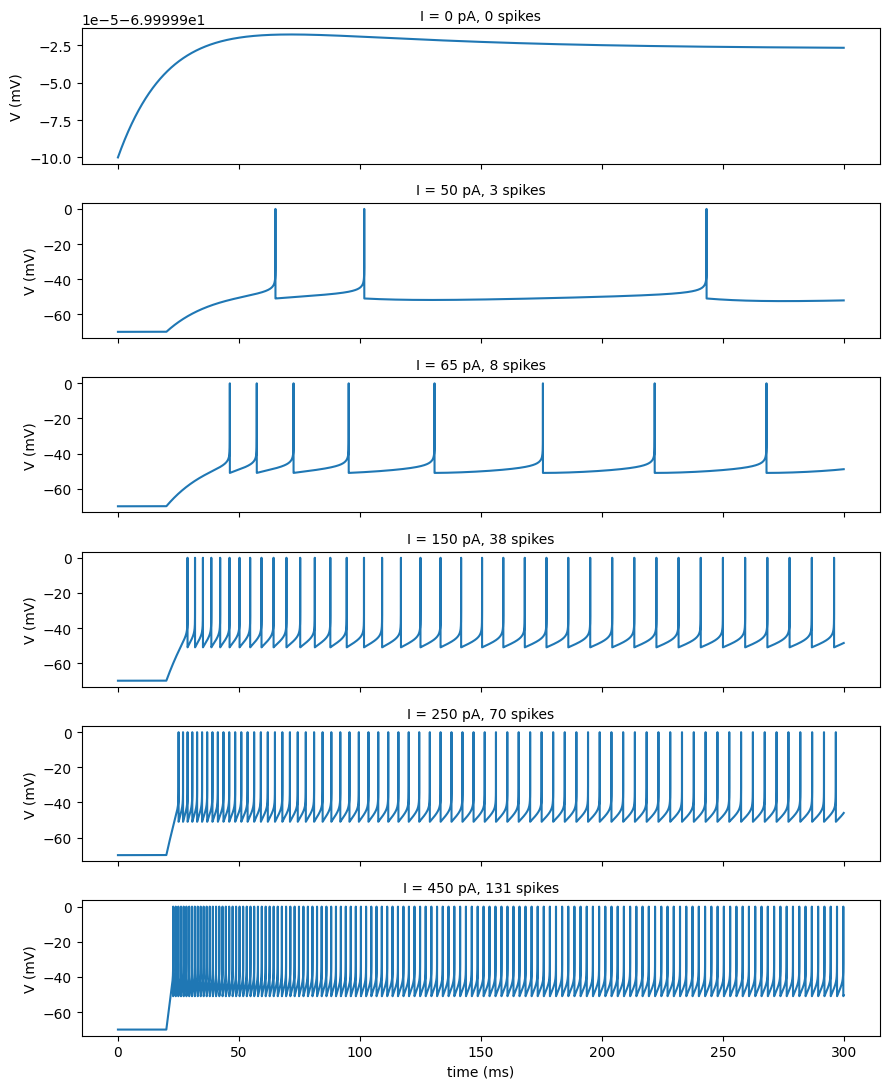

In [ ]:
currents = [0, 50, 65, 150, 250, 450]

fig, ax = plt.subplots(len(currents), 1, figsize=(9, 11), sharex=True)
for i, I in enumerate(currents):
    step = lambda t, I=I: np.where(t >= 0.02, I*1e-12, 0.0)
    t, V, w, spikes = simulate_adex(pars, step, T=0.3)
    ax[i].plot(t*1e3, V*1e3)
    ax[i].set_ylabel("V (mV)")
    ax[i].set_title(f"I = {I} pA, {len(spikes)} spikes", fontsize=10)
ax[-1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

In [ ]:
# Simulates the AdEx neuron (with given parameter values) for six different input currents in the range of 0 to 500 pA.
# Step current is applied from 20 ms and simulation time is 300 ms for each of the above input amplitudes.
# All the voltage plots are stacked in a single figure where spike counts are indicated in the figure titles.

At 0 pA, the neuron remains at rest. At 50 pA, which is slightly above the threshold, the neuron produces only 3 spikes until the adaptation process (w) stops the neuron. At 65 pA and above, the neuron begins firing repeatedly.

Each time the neuron starts firing quickly but eventually slows down with the increase in w (adaptation) until reaching its steady state.

Firing increases with an increase in current as the steady interspike interval decreases from approximately 46 ms at 65 pA (22 Hz) to 9.2 ms at 150 pA (110 Hz), 4.9 ms at 250 pA (200 Hz) and 2.6 ms at 450 pA (385 Hz).

Spike numbers per 280 ms decrease from 8 to 38, 70 and 131. In case of high currents, the effect of adaptation on the neuron is weak due to the high input current relative to the adaptation current.

**2.1.** Calculate the F-I curve by considering 100 input current magnitudes ranging from 0pA to 500pA.

Plot the fI-curve for the 3 parameter sets that you have defined above (the one provided and the two you chose in 1.2.2.). **(1 points)**

You can calculate the firing rate as the number of spikes per second while the current is on. Run the current for half a second, at different magnitudes.

I recommend to run a separate simulation for each current magnitude and record the firing rate.

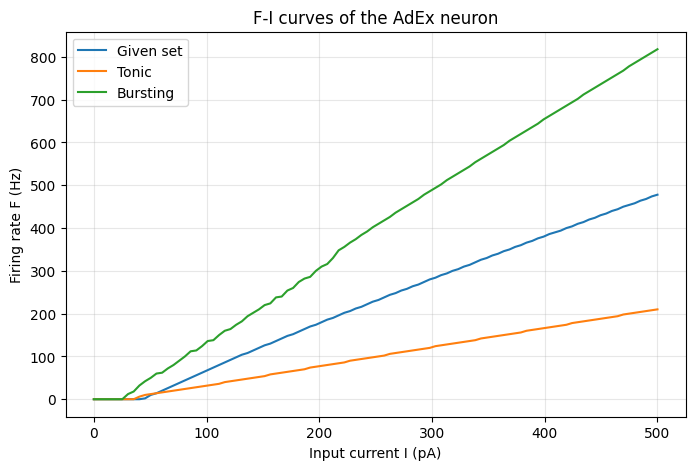

In [ ]:
T_stim = 0.5
current_vals = np.linspace(0, 500e-12, 100)
param_sets = {"Given set": pars, "Tonic": pars_tonic, "Bursting": pars_bursting}
plt.figure(figsize=(8, 5))
for name, p in param_sets.items():
    rates = [len(simulate_adex(p, I, T=T_stim)[3]) / T_stim for I in current_vals]
    plt.plot(current_vals * 1e12, rates, label=name)

plt.xlabel("Input current I (pA)")
plt.ylabel("Firing rate F (Hz)")
plt.title("F-I curves of the AdEx neuron")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Calculation and plotting of F-I curves for the provided sets, Tonic and Bursting parameter sets.
# Each set consists of simulations of 100 different currents from 0 to 500 pA for 0.5 s individually.
# Firing frequency is equal to spike count per 0.5 s stimulation period (Hz).
# All three curves are plotted to compare differences in threshold (rheobase) and slope.

All three neurons remain silent at currents below threshold and become active with a firing rate above some threshold current, the rheobase. They begin to fire at low rates (e.g., 2 Hz for the given set), which means that the graphs rise smoothly from 0 current and, therefore, show Type I behavior. Above the rheobase, their firing rate changes in proportion to the current almost linearly.

I_rh is different for the neurons because of a. The nullclines do not intersect anymore at I_rh = (G_L + a)(V_T − E_L − Δ_T + Δ_T ln(1 + a/G_L)). Thus, we obtain I_rh ≈ 46 pA for the given set (a = 0.5 nS), 36 pA for Tonic (a = 0) and 26 pA for Bursting (a = −0.5 nS), which corresponds to our simulations. The positive a value leads to a steeper w nullcline and higher currents.

The slope varies due to τm, b and Vreset. Bursting exhibits the steepest slope, where the small τm value (5 ms) causes a quick charging of V and a large Vreset value (−46 mV) allows V to approach threshold voltage rapidly after each spike. Tonic shows the least slope, since its large b value (60 pA) causes large adaptation after every spike, and a low Vreset value (−55 mV).

## 3. Phase-plane analysis
**(2.5 Points total)**

The AdEx model is a two-dimensional nonlinear dynamical system. A phase-plane diagram allows us to understand the model's behavior by studying the displacement of its state variables with time, the location and stability of its fixed points.

**3.1.** To get an initial intuition for the system's behavior, plot the (w-V)-dynamics, i.e. instead of plotting the dynamics of the state variables with time, w(t) and V(t), plot them against each other (w-V). Do this for the initial parameter set. **(0.5 Points)**


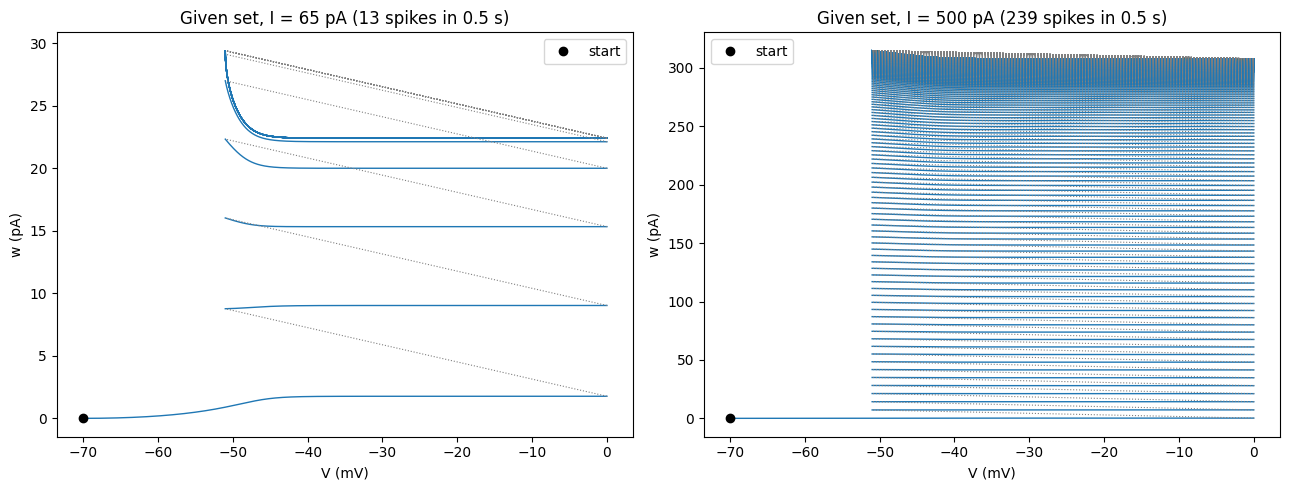

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, I in enumerate([65e-12, 500e-12]):
    t, V, w, spikes = simulate_adex(pars, I, T=0.5)
    peaks = np.where(V == pars[4])[0]                    # indices of spike peaks
    Vp = np.insert(V*1e3, peaks + 1, np.nan)             # break the line at each reset
    wp = np.insert(w*1e12, peaks + 1, np.nan)
    ax[i].plot(Vp, wp, lw=1)
    for k in peaks:                                      # draw reset jumps as dotted lines
        ax[i].plot([V[k]*1e3, V[k+1]*1e3], [w[k]*1e12, w[k+1]*1e12], ":", color="gray", lw=0.8)
    ax[i].plot(V[0]*1e3, w[0]*1e12, "ko", label="start")
    ax[i].set_xlabel("V (mV)"); ax[i].set_ylabel("w (pA)")
    ax[i].set_title(f"Given set, I = {I*1e12:.0f} pA ({len(spikes)} spikes in 0.5 s)")
    ax[i].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Plots the (V, w) phase-plane trajectory of the initial parameter set, instead of V and w over time.
# Two inputs are compared: the default 65 pA (few, easy-to-follow spikes) and 500 pA (as in Q1.1).
# Solid lines show the continuous dynamics between spikes; dotted grey lines show the resets (V to V_reset, w + b).
# The upward steps in w show adaptation, until the trajectory settles on a repeating loop (limit cycle).

**3.2.** Write an expression for the V and w nullclines and plot them in the (V, w) phase plane in the absence of input current, $I(t)=0$. Your solution should be similar to slide 42 of the lecture (although not completely the same as the parameter set is different). Also plot the vector field (note that this can be tricky to get right because of the scaling of the x and y axes, the exponential growth for higher Vs --- consider not plotting arrows for high Vs, choose a good window, and watch the scaling dependent on x and y-axis values). **(0.5 Points)**

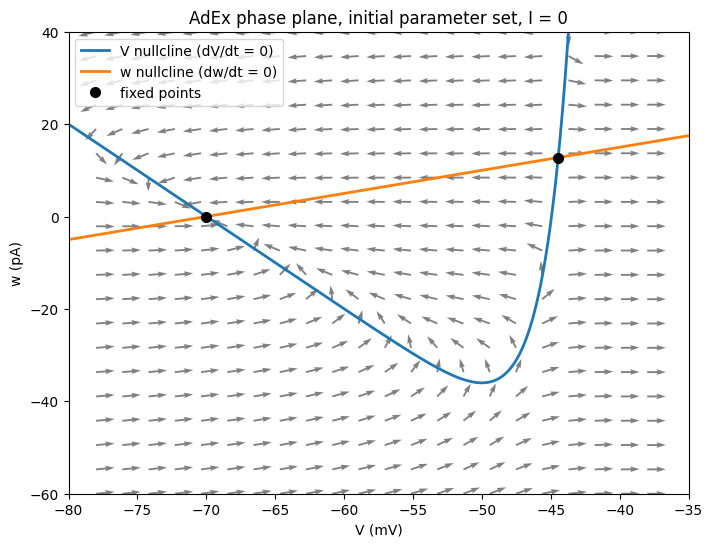

Fixed points (V in mV, w in pA): [(np.float64(-70.0), np.float64(-0.0)), (np.float64(-44.5), np.float64(12.8))]


In [ ]:
C_m, G_L, E_L, V_reset, V_peak, V_th, I_e, tau_w, Delta_T, a, b = pars
I = 0.0
V_nullcline = lambda V: -G_L*(V - E_L) + G_L*Delta_T*np.exp((V - V_th)/Delta_T) + I
w_nullcline = lambda V: a*(V - E_L)
V_range = np.linspace(-80e-3, -35e-3, 2000)
diff = V_nullcline(V_range) - w_nullcline(V_range)
fixed_V = V_range[np.where(np.diff(np.sign(diff)))[0]]
Vg, wg = np.meshgrid(np.linspace(-78e-3, -38e-3, 22), np.linspace(-60e-12, 40e-12, 20))
dV = (-G_L*(Vg - E_L) + G_L*Delta_T*np.exp((Vg - V_th)/Delta_T) - wg + I) / C_m * 1e3   # mV/s
dw = (-wg + a*(Vg - E_L)) / tau_w * 1e12                                                # pA/s
x_span, y_span, L = 45, 100, 0.03
U, W = dV/x_span, dw/y_span
norm = np.hypot(U, W)
fig, ax = plt.subplots(figsize=(8, 6))
ax.quiver(Vg*1e3, wg*1e12, U/norm*L*x_span, W/norm*L*y_span, color="gray",
          angles="xy", scale_units="xy", scale=1, width=0.003)

ax.plot(V_range*1e3, V_nullcline(V_range)*1e12, lw=2, label="V nullcline (dV/dt = 0)")
ax.plot(V_range*1e3, w_nullcline(V_range)*1e12, lw=2, label="w nullcline (dw/dt = 0)")
ax.plot(fixed_V*1e3, w_nullcline(fixed_V)*1e12, "ko", ms=7, label="fixed points")
ax.set_xlim(-80, -35); ax.set_ylim(-60, 40)
ax.set_xlabel("V (mV)"); ax.set_ylabel("w (pA)")
ax.set_title("AdEx phase plane, initial parameter set, I = 0")
ax.legend(); plt.show()
print("Fixed points (V in mV, w in pA):", [(round(v*1e3, 1), round(w_nullcline(v)*1e12, 1)) for v in fixed_V])

##Answer to 3.2

**V-nullcline** ($\frac{dV}{dt}=0$):
$$w = -G_L(V-E_L)+G_L \Delta_T \exp{\left(\frac{V-V_T}{\Delta_T}\right)}+I$$
U-shaped: The leak term is dominant for small values of $V$ and the exponential for values greater than $V_T$. It has its minimum point at $V=V_T=-50$ mV, $w=-36$ pA (with $I=0$).

**w-nullcline** ($\frac{dw}{dt}=0$):
$$w = a(V-E_L)$$
It is a straight line passing through point $(E_L,0)$ with slope $a = 0.5$ nS.

**Fixed points ($I=0$):** There is a stable node at $(-70\text{ mV},0\text{ pA})$ corresponding to the resting state and a saddle at $(-44.5\text{ mV},12.8\text{ pA})$ serving as the threshold.

**Vector field:** For values of $V$ less than $V$-nullcline, there is an increase in $V$ (the arrows point to the right) and for values of $V$ greater than $V$-nullcline there is a decrease in $V$. For values of $w$ less than $w$-nullcline, there is an increase in $w$ and for values of $w$ greater than $w$-nullcline there is a decrease in $w$.

**3.3.** How do the nullclines change with respect to the sub-threshold adaptation parameter $a$ and applied current $I_\text{stim}$?  Plot some examples and describe. **(0.5 Points)**

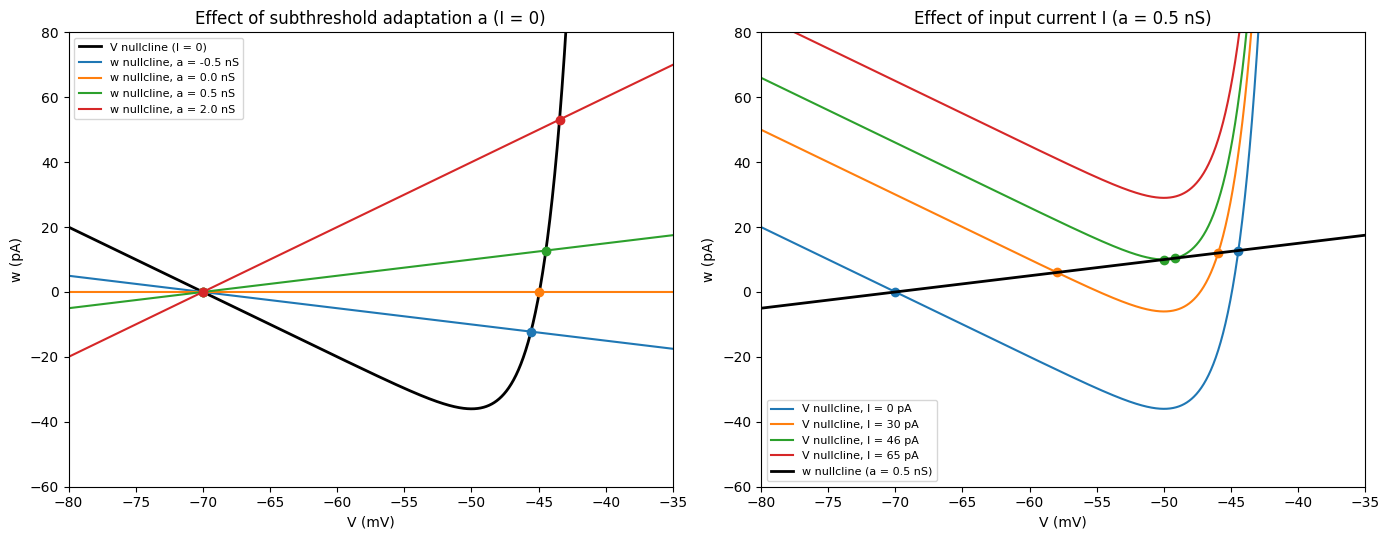

In [ ]:
C_m, G_L, E_L, V_reset, V_peak, V_th, I_e, tau_w, Delta_T, a, b = pars
V_range = np.linspace(-80e-3, -35e-3, 2000)
V_null = lambda V, I: -G_L*(V - E_L) + G_L*Delta_T*np.exp((V - V_th)/Delta_T) + I
w_null = lambda V, a_: a_*(V - E_L)
def fixed_points(a_, I):
    d = V_null(V_range, I) - w_null(V_range, a_)
    return V_range[np.where(np.diff(np.sign(d)))[0]]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].plot(V_range*1e3, V_null(V_range, 0)*1e12, "k", lw=2, label="V nullcline (I = 0)")
for a_ in [-0.5e-9, 0.0, 0.5e-9, 2e-9]:
    line, = ax[0].plot(V_range*1e3, w_null(V_range, a_)*1e12, label=f"w nullcline, a = {a_*1e9} nS")
    fp = fixed_points(a_, 0)
    ax[0].plot(fp*1e3, w_null(fp, a_)*1e12, "o", color=line.get_color())
ax[0].set_title("Effect of subthreshold adaptation a (I = 0)")
for I in [0, 30e-12, 46e-12, 65e-12]:
    line, = ax[1].plot(V_range*1e3, V_null(V_range, I)*1e12, label=f"V nullcline, I = {I*1e12:.0f} pA")
    fp = fixed_points(a, I)
    ax[1].plot(fp*1e3, w_null(fp, a)*1e12, "o", color=line.get_color())
ax[1].plot(V_range*1e3, w_null(V_range, a)*1e12, "k", lw=2, label="w nullcline (a = 0.5 nS)")
ax[1].set_title("Effect of input current I (a = 0.5 nS)")

for x in ax:
    x.set_xlim(-80, -35); x.set_ylim(-60, 80)
    x.set_xlabel("V (mV)"); x.set_ylabel("w (pA)"); x.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Shows the variation of the AdEx nullclines due to the subthreshold adaptation parameter a (on the left) and the input current I (on the right).
# Dots indicate the location of the fixed points (intersection of nullclines).
# Effect of a: Only w nullcline w = a(V-E_L) varies. It rotates around (E_L, 0):
#  increasing a makes the line steeper, a = 0 means flat line, and a < 0 makes it downward.
#  The rest point remains at -70 mV, but the saddle (threshold) moves up and to the right
#  (from -45.6 mV at a = -0.5 nS to -43.4 mV at a = 2 nS).
#  Higher steepness implies higher current required for the non-intersection of the nullclines, therefore higher rheobase due to larger a.
# Effect of I: Only V nullcline is changed. It moves vertically upward by the value of I and preserves the U shape.
#As I grows, the rest point and the saddle approach each other (-58 and -46 mV at I = 30 pA),
# coincide at the vicinity of V_T at about 46 pA (saddle node bifurcation) and disappear for I > 65 pA.
# Without any fixed point, the neuron cannot rest and produces repetitive firing.

**3.4.** For the initial parameter set, plot the w-V curve on top of the nullclines for one spike, and then for several spikes (e.g., if the spiking behavior is 'tonic', explain why it is so). Explain the spiking behavior using this. This analysis should be similar to slides 43 and 44 from the lecture. **(1 Points)**

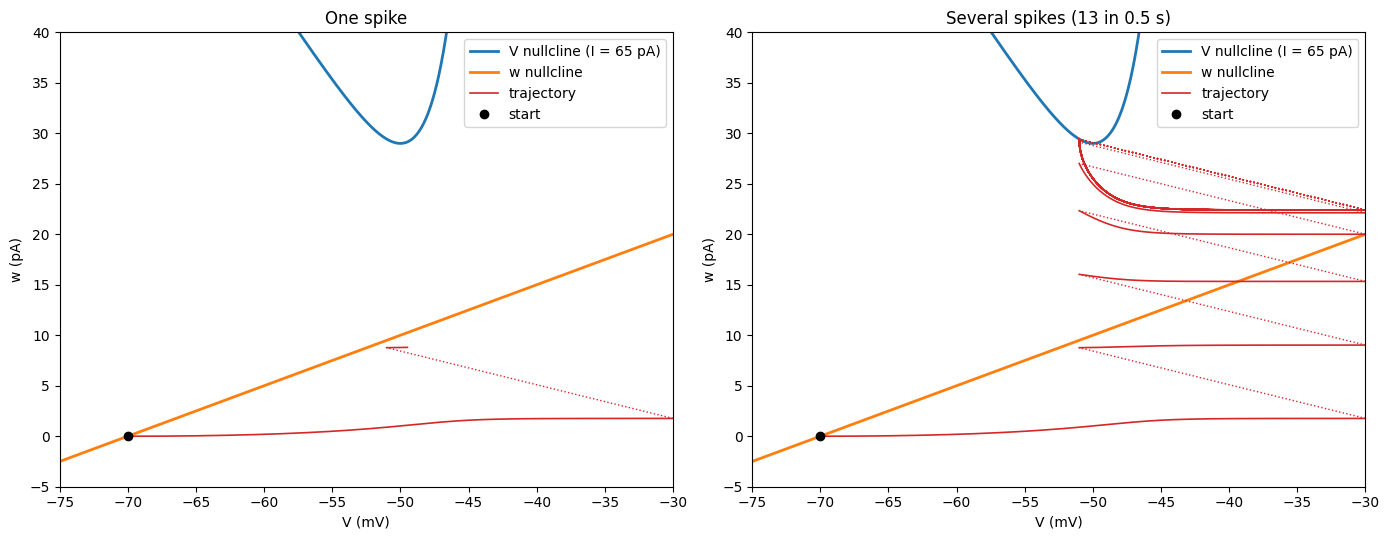

w after each reset (pA): [ 8.8 16.  22.3 27.  29.1 29.4 29.4 29.4]


In [ ]:
C_m, G_L, E_L, V_reset, V_peak, V_th, I_e, tau_w, Delta_T, a, b = pars
I = I_e
V_range = np.linspace(-75e-3, -30e-3, 1000)
V_null = lambda V: -G_L*(V - E_L) + G_L*Delta_T*np.exp((V - V_th)/Delta_T) + I
w_null = lambda V: a*(V - E_L)
def plot_trajectory(ax, V, w, x_cut=-30):
    peaks = np.where(V == V_peak)[0]
    Vp = np.insert(V*1e3, peaks + 1, np.nan)
    wp = np.insert(w*1e12, peaks + 1, np.nan)
    ax.plot(Vp, wp, "C3", lw=1.2, label="trajectory")
    for k in peaks:
        ax.plot([x_cut, V[k+1]*1e3], [w[k]*1e12, w[k+1]*1e12], ":", color="C3", lw=1)
    ax.plot(V[0]*1e3, w[0]*1e12, "ko", label="start")

t, V, w, spikes = simulate_adex(pars, I, T=0.5)
end_one = np.searchsorted(t, spikes[0]) + 300
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for i, (sl, title) in enumerate([(slice(0, end_one), "One spike"),
                                 (slice(None), f"Several spikes ({len(spikes)} in 0.5 s)")]):
    ax[i].plot(V_range*1e3, V_null(V_range)*1e12, lw=2, label="V nullcline (I = 65 pA)")
    ax[i].plot(V_range*1e3, w_null(V_range)*1e12, lw=2, label="w nullcline")
    plot_trajectory(ax[i], V[sl], w[sl])
    ax[i].set_xlim(-75, -30); ax[i].set_ylim(-5, 40)
    ax[i].set_xlabel("V (mV)"); ax[i].set_ylabel("w (pA)")
    ax[i].set_title(title); ax[i].legend()
plt.tight_layout(); plt.show()
print("w after each reset (pA):", np.round(w[np.where(V == V_peak)[0] + 1][:8]*1e12, 1))

In [ ]:
# Phase-plane analysis of the Tonic and Bursting sets (65 pA). Both have identical V nullcline
# (minimum of -50 mV, 29 pA), but different a, V_reset, b, and tau_w.
# Tonic: all resets happen at (-55 mV, approx. 70 pA), above the V nullcline (35 pA at -55 mV),
# so V first drops, the trajectory wraps around the U shape while w declines.
# Short tau_w (30 ms) causes w to return to approx. 10 pA per cycle, which makes all loops identical, constant ISI and tonic spiking.
# Bursting: V_reset = -46 mV is located on the right branch of the U (47 pA there).
# All resets below 47 pA fall below the nullcline, making V escape immediately: fast spikes, each incrementing b = 7 pA.
# If a reset falls above 47 pA, V drops, burst ends; w slowly declines (tau_w = 100 ms)
# until the trajectory goes below the minimum of U (approx. 23 pA) and another burst begins.

**3.4 (BONUS).** Use the analysis you developped above to explain the spiking behavior of your other two chosen parameter sets. **(0.25 bonus points per parameter set explained)**

Tonic: w after each reset (pA): [60.  70.  69.7 69.7 69.7 69.7 69.7]
Bursting: w after each reset (pA): [ 6.5 13.4 20.2 27.  33.6 40.1 46.3 51.6 30.2 36.8 43.2 49.2]


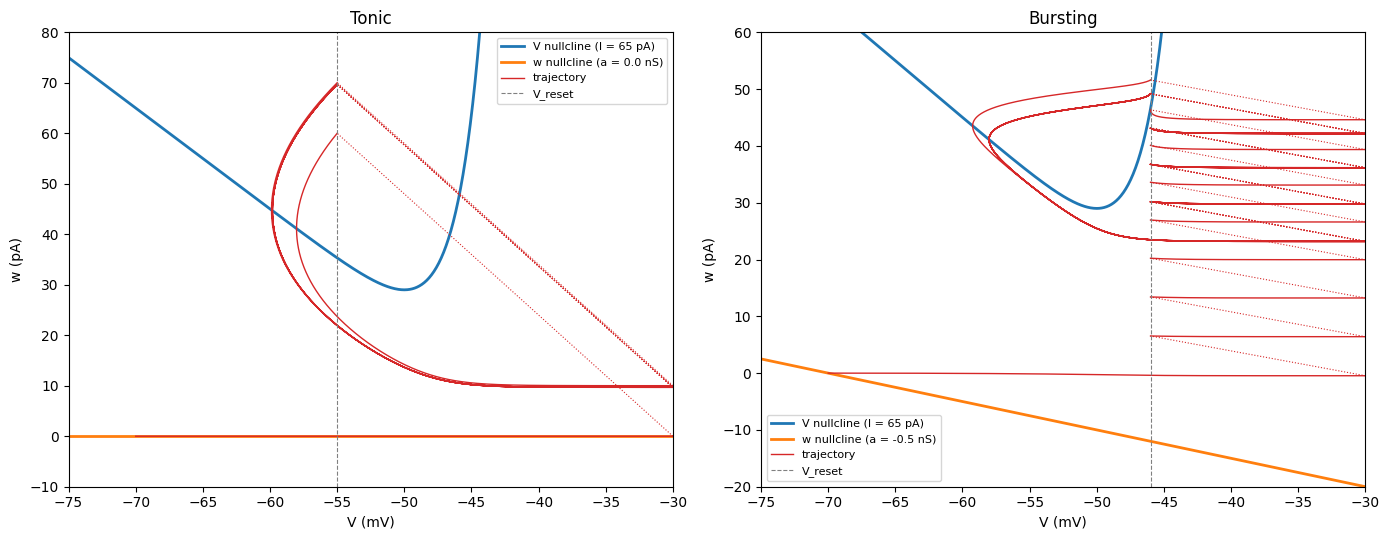

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for i, (p, name, ylim) in enumerate([(pars_tonic, "Tonic", (-10, 80)), (pars_bursting, "Bursting", (-20, 60))]):
    C_m, G_L, E_L, V_reset, V_peak, V_th, I, tau_w, Delta_T, a, b = p
    V_range = np.linspace(-75e-3, -30e-3, 1000)
    ax[i].plot(V_range*1e3, (-G_L*(V_range - E_L) + G_L*Delta_T*np.exp((V_range - V_th)/Delta_T) + I)*1e12,
               lw=2, label="V nullcline (I = 65 pA)")
    ax[i].plot(V_range*1e3, a*(V_range - E_L)*1e12, lw=2, label=f"w nullcline (a = {a*1e9} nS)")
    t, V, w, spikes = simulate_adex(p, I, T=0.4)
    peaks = np.where(V == V_peak)[0]
    ax[i].plot(np.insert(V*1e3, peaks + 1, np.nan), np.insert(w*1e12, peaks + 1, np.nan), "C3", lw=1, label="trajectory")
    for k in peaks:
        ax[i].plot([-30, V[k+1]*1e3], [w[k]*1e12, w[k+1]*1e12], ":", color="C3", lw=0.8)
    ax[i].axvline(V_reset*1e3, color="gray", ls="--", lw=0.8, label="V_reset")
    ax[i].set_xlim(-75, -30); ax[i].set_ylim(*ylim)
    ax[i].set_xlabel("V (mV)"); ax[i].set_ylabel("w (pA)"); ax[i].set_title(name); ax[i].legend(fontsize=8)
    print(f"{name}: w after each reset (pA):", np.round(w[peaks + 1][:12]*1e12, 1))
plt.tight_layout(); plt.show()

In [ ]:
# Phase plane analysis for the Tonic and Bursting parameter sets (Section 1.2.2), each with an input of 65 pA.
# Both use the same V nullcline (minima at -50 mV, 29 pA), differing only in values of a, V_reset, b and tau_w.
# Dotted lines represent resets (V to V_reset, increase in w by b).
# Tonic: all resets occur at (-55 mV, about 70 pA), which is above the V nullcline (35 pA at -55 mV),
# causing V to decrease in the beginning and the loop goes to the left around the U shape with w decaying.
# Low tau_w (30 ms) enables w to decay to 10 pA each time, resulting in identical loops: constant ISI, tonic spiking.
# Bursting: the V_reset = -46 mV occurs at the right branch of the U (47 pA there).
# All resets occurring below 47 pA are located below the nullcline, resulting in escaping V and fast spikes,
# with each spike increasing w by b = 7 pA. In case of the reset above 47 pA, V decreases and bursting stops;
# w decays slowly (tau_w = 100 ms) until the loop reaches below the U minima (23 pA), initiating a new burst.

# 4 (*For background interest*) Signal encoding  with neuronal dynamics

Now that you have a solid understanding of the AdEx model and its responsiveness, take a look at the example notebook, [AdEx-encoder-example](./AdEx-encoder-example.ipynb) that demonstrates a simple use case where the complexity of the neuron's fI curve and nonlinearities are used to encode a time-dependent input signal. For those following neuromorphic engineering and/or computing this one is of particular interest.

**Note:** This part is just a curiosity, there is no evaluation involved. You won't be able to run the model in that notebook without installing Nest. We have prerun everything in the notebook so you can see the outputs without having to run Nest.


# 5 Exam perspective and example question
In the exam you will be expected to be able to handle all of the above mathematically and intuitively, without the need to simulate anything. You would also be expected to be able to do this for similar models like the 2-variable reduced H&H model, the Izhikevich neuron, or other similar models. In all cases you would be given the required mathematics and background, so no need to memorize by heart all the possible neuron models out there, of course --- instead you truly build an in-depth understanding of the mathematics, how this leads to the nullclines and phase-plots, and how the model behaves given those. You might be asked to sketch out trajectories on phase-plots and over time (e.g. how $w$ behaves over time), derive and sketch nullclines and fixed points, and similar things.

Example for the model you made above:

### Exam question (not graded for this assignment, just an example)
Consider the Adaptive Exponential (`AdEx') neuron model. It is a 2-dimensional adaptive nonlinear integrate-and-fire model. The sub-threshold dynamics is given by:

$$C_{m} \frac{dV_{m}}{dt} = -G_{\mathrm{L}} (V_{m} - E_{L}) + G_{\mathrm{L}} \Delta_{\mathrm{T}} \mathrm{exp}\left( \frac{(V_{m} - V_{\mathrm{T}})}{\Delta_{\mathrm{T}}} \right) - w + I_{\mathrm{stim}}$$

$$\tau_{w} \frac{dw}{dt} = -w + a\cdot (V_{m} - E_{L}) +b\cdot\delta(t-t_f)$$

We choose a parameter set such that the phase plane is as in Fig.~[figure similar to your own phase planes above].

The spiking mechanism is as follows: when the membrane crosses a hard threshold $V_\text{peak}$, the membrane is reset to $V_{\mathrm{reset}}$ and $w$ is increased by $b$ (through the $b\cdot\delta(t-t_f)$ term).

1. What is the effect of the current `w' after a spike on the $w$ and $V$ dynamics? Explain mathematically and with the phase-plot.
2. What is the effect $V_m$ going higher than $V_T$? Explain mathematically and with the phase-plot.
3. Compared to the H&H model, what is the exponential term meant to model?
4. Let the parameter `b' be 0.02 nA. The spiking threshold $V_\text{peak}=0$. X marks the starting $V_m$ and $w$ values [would be a starting parameter in the phase-plane]. Note that all other parameter values are not necessary to know exactly in order to answer the questions below since the phase-plane is plotted for you.

   a. In the phase portrait, draw the ($V_m$, $w$) trajectories for at least \textbf{seven} spikes. You may instead also sketch a similar phase portrait with just the nullclines, and sketch in there (e.g. if you want to redo your initial sketch). It is possible trajectories overlap.

   b. Additionally sketch the corresponding membrane voltage over time in a new plot.
5. In the assignments and lectures we considered the following types of spiking pattern types: Tonic, Adapting, Initial burst, Bursting, Irregular, Transient, Delayed.  How would you characterize the type of spiking you sketched, and why? Explain how this pattern emerges in words, refer to the phase-plane plot.
   